In [4]:
!pip -q install segmentation-models-pytorch rasterio opencv-python tifffile

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 4.6 MB/s eta 0:00:00


In [5]:
import os
import glob
import cv2
import rasterio
import tifffile
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

import segmentation_models_pytorch as smp

In [6]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

Device : cuda
GPU : Tesla T4


In [7]:
UNET_PATH = None
CONVLSTM_PATH = None

for root, dirs, files in os.walk("/kaggle/input"):

    for file in files:

        if file == "unet_fire_segmentation_final.pth":
            UNET_PATH = os.path.join(root, file)

        if file == "future_fire_prediction.pth":
            CONVLSTM_PATH = os.path.join(root, file)

print("UNET :", UNET_PATH)
print("CONVLSTM :", CONVLSTM_PATH)

UNET : /kaggle/input/datasets/nithinbr2005/unet-fire-segmentation-final4/unet_fire_segmentation_final.pth
CONVLSTM : /kaggle/input/datasets/nithinbr2005/future-fire-prediction4/future_fire_prediction.pth


In [8]:
thermal_files = sorted(

    glob.glob(
        "/kaggle/input/**/*.TIFF",
        recursive=True
    )

)

thermal_files = [

    f for f in thermal_files

    if "geo_thermal_tiff_celsius" in f

]

print("Total Images :", len(thermal_files))

Total Images : 794


In [9]:
unet = smp.Unet(

    encoder_name="resnet34",

    encoder_weights=None,

    in_channels=3,

    classes=1

)

In [10]:
unet_checkpoint = torch.load(

    UNET_PATH,

    map_location=device

)

unet.load_state_dict(

    unet_checkpoint["model_state_dict"]

)

threshold = unet_checkpoint["threshold"]

unet = unet.to(device)

unet.eval()

print("U-Net Loaded")
print("Threshold :", threshold)

U-Net Loaded
Threshold : 0.3


In [17]:
class ConvLSTMCell(nn.Module):

    def __init__(self,input_channels,hidden_channels,kernel_size=3):

        super().__init__()

        padding=kernel_size//2

        self.hidden_channels=hidden_channels

        self.conv=nn.Conv2d(
            input_channels+hidden_channels,
            4*hidden_channels,
            kernel_size,
            padding=padding
        )

    def forward(self,x,h,c):

        combined=torch.cat([x,h],dim=1)

        gates=self.conv(combined)

        i,f,o,g=torch.chunk(gates,4,dim=1)

        i=torch.sigmoid(i)
        f=torch.sigmoid(f)
        o=torch.sigmoid(o)
        g=torch.tanh(g)

        c=f*c+i*g

        h=o*torch.tanh(c)

        return h,c

In [28]:
class ConvLSTM(nn.Module):

    def __init__(self):

        super().__init__()

        self.hidden_channels=32

        self.cell=ConvLSTMCell(

            input_channels=1,

            hidden_channels=self.hidden_channels

        )

        self.output=nn.Conv2d(

            self.hidden_channels,

            1,

            kernel_size=1

        )

    def forward(self,x):

        batch,seq,ch,h,w=x.size()

        hidden=torch.zeros(

            batch,

            self.hidden_channels,

            h,

            w,

            device=x.device

        )

        cell=torch.zeros_like(hidden)

        for t in range(seq):

            hidden,cell=self.cell(

                x[:,t],

                hidden,

                cell

            )

        return self.output(hidden)

In [29]:
convlstm = ConvLSTM().to(device)

checkpoint = torch.load(

    CONVLSTM_PATH,

    map_location=device

)

# Supports both checkpoint formats
if isinstance(checkpoint, dict) and "model_state_dict" in checkpoint:
    convlstm.load_state_dict(checkpoint["model_state_dict"])
else:
    convlstm.load_state_dict(checkpoint)

convlstm.eval()

print("ConvLSTM Loaded Successfully")

ConvLSTM Loaded Successfully


In [36]:
def preprocess(path):

    with rasterio.open(path) as src:
        img = src.read(1)

    img = np.nan_to_num(img)

    img = (img - img.min()) / (img.max() - img.min() + 1e-8)

    img = (img * 255).astype(np.uint8)

    img = cv2.resize(img, (256, 256))

    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)

    tensor = torch.from_numpy(
        rgb.astype(np.float32) / 255.0
    ).permute(2, 0, 1).unsqueeze(0)

    return img, tensor

In [37]:
SEQUENCE_LENGTH = 5

folder = "/kaggle/input/datasets/brycehopkins/flame-3-nadir-thermal-plot-subset/Hanna Hammock/plot 1/duringburn/geo_thermal_tiff_celsius"

sequence_files = sorted(
    glob.glob(folder + "/*.TIFF")
)

sequence_files = sequence_files[:SEQUENCE_LENGTH]

print("Frames Selected:")

for f in sequence_files:
    print(os.path.basename(f))

Frames Selected:
IRX_0529_ref_geo.TIFF
IRX_0530_ref_geo.TIFF
IRX_0531_ref_geo.TIFF
IRX_0532_ref_geo.TIFF
IRX_0533_ref_geo.TIFF


In [38]:
fire_masks = []

thermal_images = []

for path in sequence_files:

    image, tensor = preprocess(path)

    thermal_images.append(image)

    tensor = tensor.to(device)

    with torch.no_grad():

        pred = unet(tensor)

        pred = torch.sigmoid(pred)

        mask = (pred > threshold).float()

    fire_masks.append(
        mask.squeeze().cpu().numpy()
    )

print("Generated:", len(fire_masks), "Masks")

Generated: 5 Masks


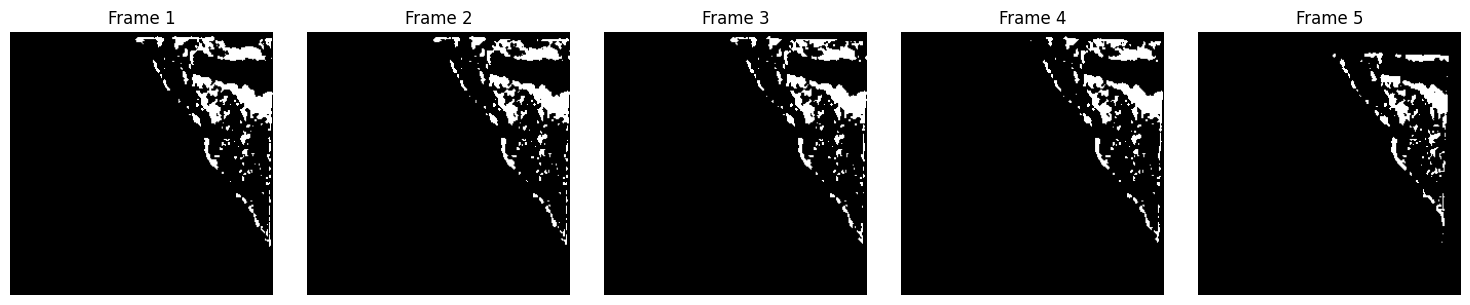

In [39]:
plt.figure(figsize=(15,3))

for i in range(5):

    plt.subplot(1,5,i+1)

    plt.imshow(fire_masks[i], cmap="gray")

    plt.title(f"Frame {i+1}")

    plt.axis("off")

plt.tight_layout()

plt.show()

In [40]:
sequence = np.array(
    fire_masks,
    dtype=np.float32
)

sequence = torch.tensor(sequence)

sequence = sequence.unsqueeze(1)

sequence = sequence.unsqueeze(0)

sequence = sequence.to(device)

print(sequence.shape)

torch.Size([1, 5, 1, 256, 256])


In [41]:
with torch.no_grad():

    prediction = convlstm(sequence)

    prediction = torch.sigmoid(prediction)

future_mask = (
    prediction > 0.5
).float()

future_mask = future_mask.squeeze().cpu().numpy()

print("Prediction Complete")

Prediction Complete


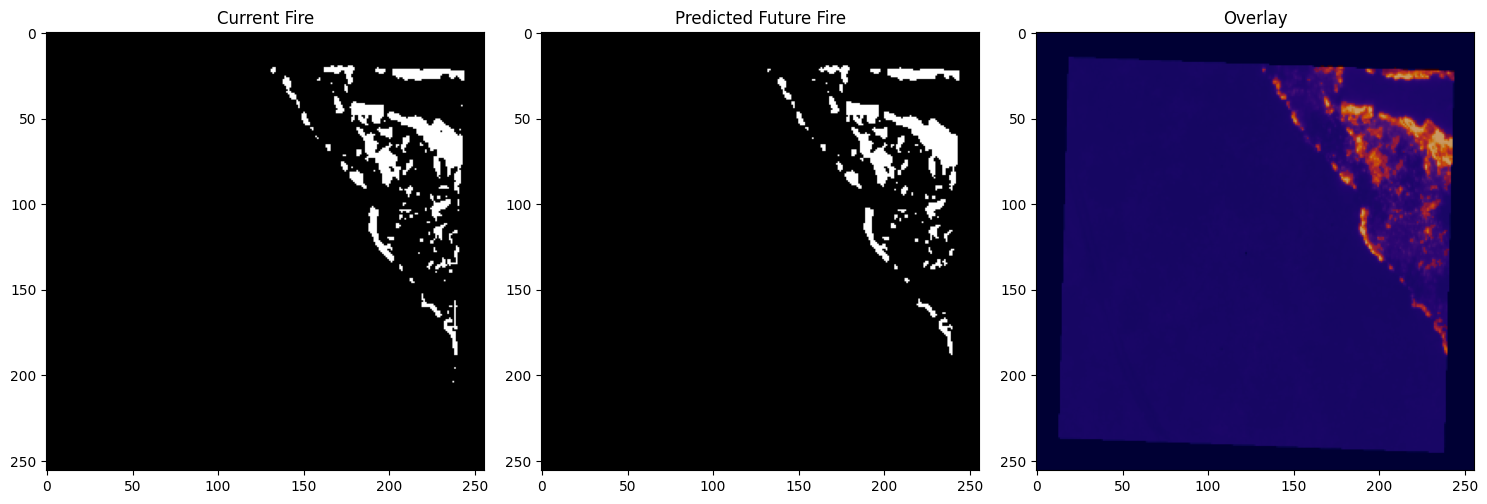

In [42]:
plt.figure(figsize=(15,5))

plt.subplot(1,3,1)
plt.imshow(fire_masks[-1], cmap="gray")
plt.title("Current Fire")

plt.subplot(1,3,2)
plt.imshow(future_mask, cmap="gray")
plt.title("Predicted Future Fire")

plt.subplot(1,3,3)
plt.imshow(thermal_images[-1], cmap="inferno")
plt.imshow(
    future_mask,
    alpha=0.4,
    cmap="jet"
)
plt.title("Overlay")

plt.tight_layout()

plt.show()

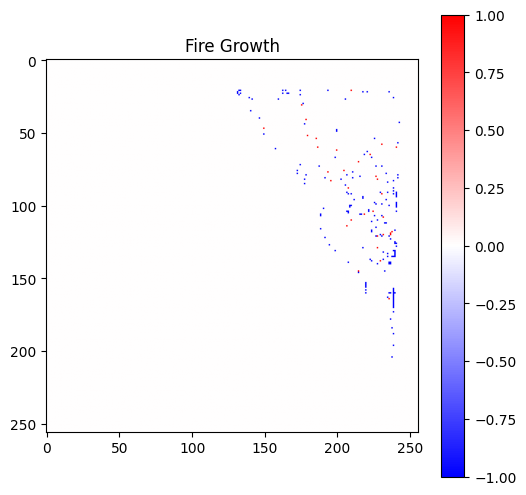

Changed Pixels: 205.0


In [44]:
difference = future_mask - fire_masks[-1]

plt.figure(figsize=(6,6))

plt.imshow(
    difference,
    cmap="bwr"
)

plt.colorbar()

plt.title("Fire Growth")

plt.show()

print(
    "Changed Pixels:",
    np.sum(np.abs(difference))
)

In [45]:
current_pixels = np.sum(fire_masks[-1])

future_pixels = np.sum(future_mask)

print("Current Fire Pixels :", current_pixels)

print("Future Fire Pixels :", future_pixels)

print(
    "Increase :",
    future_pixels-current_pixels
)

Current Fire Pixels : 2407.0
Future Fire Pixels : 2268.0
Increase : -139.0


In [46]:
np.save(
    "predicted_future_fire.npy",
    future_mask
)

print("Saved Successfully")

Saved Successfully


In [47]:
import cv2

current_mask = (fire_masks[-1] * 255).astype(np.uint8)
future_binary = (future_mask * 255).astype(np.uint8)

current_contours, _ = cv2.findContours(
    current_mask,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

future_contours, _ = cv2.findContours(
    future_binary,
    cv2.RETR_EXTERNAL,
    cv2.CHAIN_APPROX_SIMPLE
)

print("Current Boundaries :", len(current_contours))
print("Future Boundaries :", len(future_contours))

Current Boundaries : 72
Future Boundaries : 62


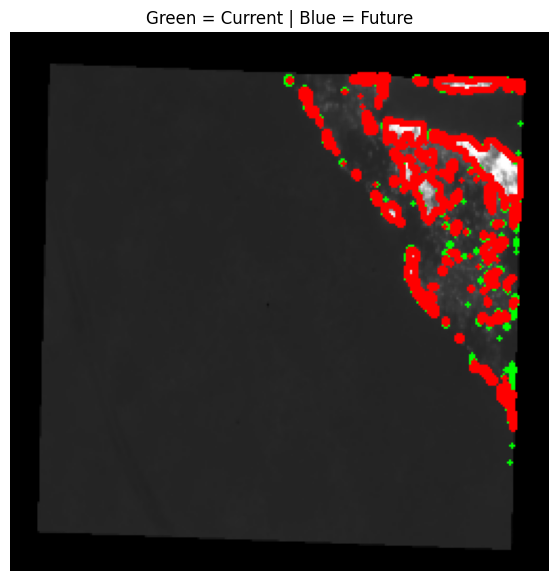

In [48]:
boundary = cv2.cvtColor(thermal_images[-1], cv2.COLOR_GRAY2RGB)

cv2.drawContours(
    boundary,
    current_contours,
    -1,
    (0,255,0),
    2
)

cv2.drawContours(
    boundary,
    future_contours,
    -1,
    (255,0,0),
    2
)

plt.figure(figsize=(7,7))
plt.imshow(boundary)
plt.title("Green = Current | Blue = Future")
plt.axis("off")
plt.show()

In [49]:
def get_center(mask):

    ys, xs = np.where(mask > 0)

    if len(xs) == 0:
        return None

    return (
        np.mean(xs),
        np.mean(ys)
    )

current_center = get_center(fire_masks[-1])
future_center = get_center(future_mask)

print("Current Center :", current_center)
print("Future Center :", future_center)

Current Center : (np.float64(208.20232654756958), np.float64(73.77897798088907))
Future Center : (np.float64(207.79409171075838), np.float64(71.85714285714286))


In [50]:
dx = future_center[0] - current_center[0]
dy = future_center[1] - current_center[1]

print("dx =", dx)
print("dy =", dy)

angle = np.degrees(np.arctan2(dy, dx))

print("Angle =", angle)

dx = -0.40823483681120365
dy = -1.921835123746206
Angle = -101.99247424182674


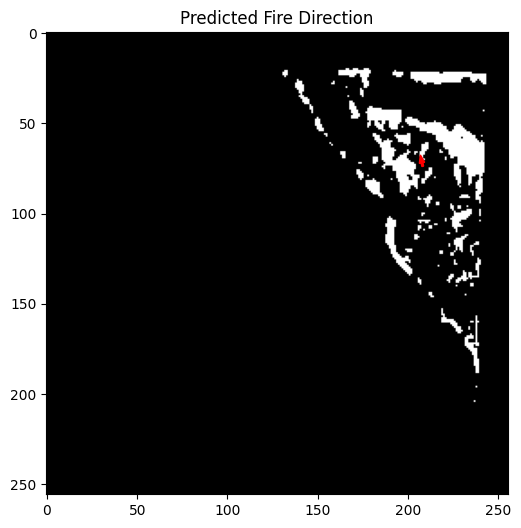

In [51]:
plt.figure(figsize=(6,6))

plt.imshow(fire_masks[-1], cmap="gray")

plt.arrow(
    current_center[0],
    current_center[1],
    dx,
    dy,
    color="red",
    width=1
)

plt.title("Predicted Fire Direction")

plt.show()

In [52]:
distance = np.sqrt(dx**2 + dy**2)

print("Spread Distance :", distance)

Spread Distance : 1.9647152274186874


In [53]:
minutes = 1

speed = distance / minutes

print("Spread Speed :", speed, "pixels/minute")

Spread Speed : 1.9647152274186874 pixels/minute


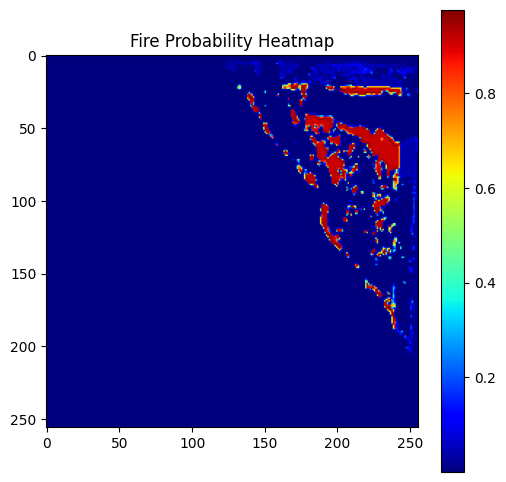

In [54]:
probability = prediction.squeeze().cpu().numpy()

plt.figure(figsize=(6,6))

plt.imshow(
    probability,
    cmap="jet"
)

plt.colorbar()

plt.title("Fire Probability Heatmap")

plt.show()

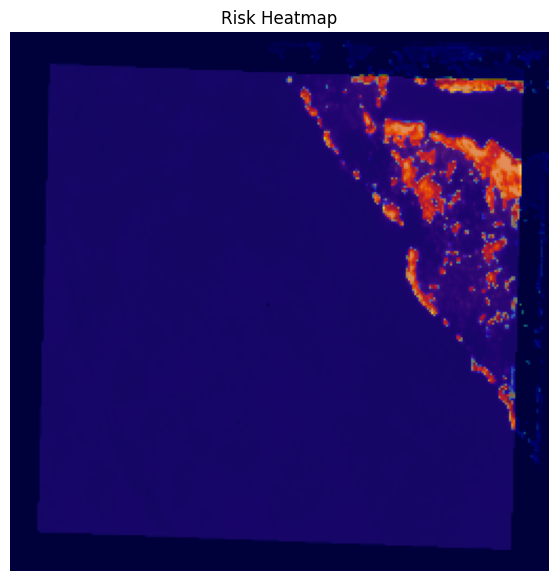

In [55]:
plt.figure(figsize=(7,7))

plt.imshow(
    thermal_images[-1],
    cmap="inferno"
)

plt.imshow(
    probability,
    alpha=0.45,
    cmap="jet"
)

plt.title("Risk Heatmap")

plt.axis("off")

plt.show()

In [57]:
print("="*40)

print("Current Fire Area :", current_pixels)

print("Predicted Fire Area :", future_pixels)

print("Area Difference :", future_pixels-current_pixels)

print("Spread Distance :", distance)

print("Spread Speed :", speed)

print("Direction Angle :", angle)

print("="*40)

Current Fire Area : 2407.0
Predicted Fire Area : 2268.0
Area Difference : -139.0
Spread Distance : 1.9647152274186874
Spread Speed : 1.9647152274186874
Direction Angle : -101.99247424182674


In [58]:
# Cell 31

change = future_pixels - current_pixels

if change > 500:
    risk = "HIGH"
elif change > 100:
    risk = "MEDIUM"
else:
    risk = "LOW"

print("Fire Risk Level:", risk)

Fire Risk Level: LOW


In [59]:
# Cell 32

growth = ((future_pixels - current_pixels) /
          max(current_pixels, 1)) * 100

print(f"Growth Percentage: {growth:.2f}%")

Growth Percentage: -5.77%


In [60]:
# Cell 33

import cv2

cv2.imwrite(
    "predicted_future_fire.png",
    (future_mask * 255).astype(np.uint8)
)

print("Prediction image saved.")

Prediction image saved.


In [61]:
# Cell 34

plt.figure(figsize=(6,6))

plt.imshow(probability, cmap="jet")
plt.axis("off")

plt.savefig(
    "fire_probability_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Heatmap saved.")

Heatmap saved.


In [62]:
# Cell 35

plt.figure(figsize=(6,6))

plt.imshow(thermal_images[-1], cmap="inferno")
plt.imshow(probability, cmap="jet", alpha=0.45)

plt.axis("off")

plt.savefig(
    "future_fire_overlay.png",
    dpi=300,
    bbox_inches="tight"
)

plt.close()

print("Overlay saved.")

Overlay saved.


In [63]:
# Cell 36

import pandas as pd

results = pd.DataFrame({
    "Current Area":[current_pixels],
    "Future Area":[future_pixels],
    "Area Difference":[future_pixels-current_pixels],
    "Spread Distance":[distance],
    "Spread Speed":[speed],
    "Direction Angle":[angle],
    "Risk":[risk]
})

results.to_csv(
    "prediction_results.csv",
    index=False
)

results

,Current Area,Future Area,Area Difference,Spread Distance,Spread Speed,Direction Angle,Risk
0,2407.0,2268.0,-139.0,1.964715,1.964715,-101.992474,LOW


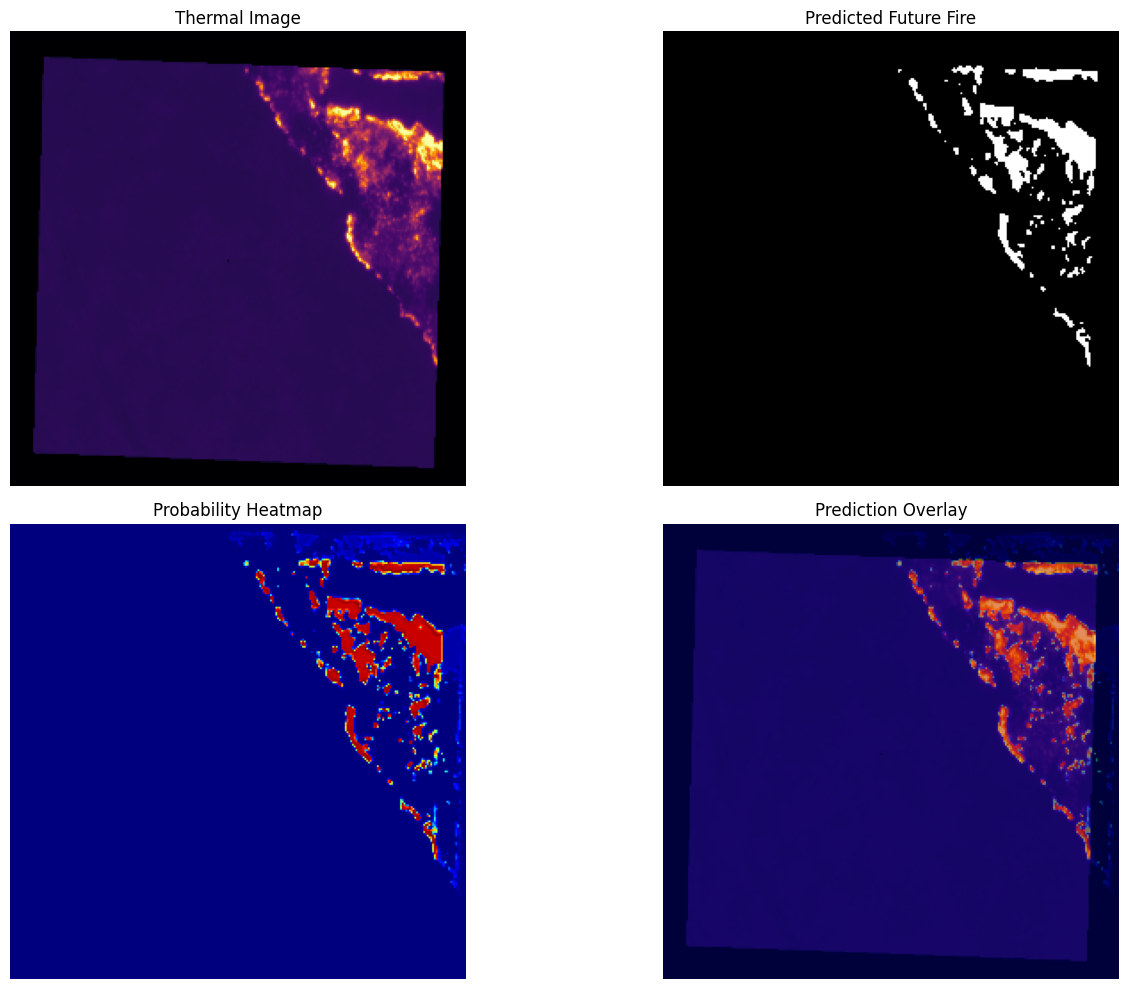

In [64]:
# Cell 37

fig = plt.figure(figsize=(15,10))

plt.subplot(2,2,1)
plt.imshow(thermal_images[-1], cmap="inferno")
plt.title("Thermal Image")
plt.axis("off")

plt.subplot(2,2,2)
plt.imshow(future_mask, cmap="gray")
plt.title("Predicted Future Fire")
plt.axis("off")

plt.subplot(2,2,3)
plt.imshow(probability, cmap="jet")
plt.title("Probability Heatmap")
plt.axis("off")

plt.subplot(2,2,4)
plt.imshow(thermal_images[-1], cmap="inferno")
plt.imshow(probability, cmap="jet", alpha=0.45)
plt.title("Prediction Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

In [65]:
# Cell 38

print("=" * 60)
print("Future Wildfire Prediction Summary")
print("=" * 60)

print(f"Current Fire Area     : {current_pixels:.0f} pixels")
print(f"Predicted Fire Area   : {future_pixels:.0f} pixels")
print(f"Area Difference       : {future_pixels-current_pixels:.0f} pixels")
print(f"Spread Distance       : {distance:.2f} pixels")
print(f"Spread Speed          : {speed:.2f} pixels/minute")
print(f"Direction Angle       : {angle:.2f}°")
print(f"Risk Level            : {risk}")

print("=" * 60)

Future Wildfire Prediction Summary
Current Fire Area     : 2407 pixels
Predicted Fire Area   : 2268 pixels
Area Difference       : -139 pixels
Spread Distance       : 1.96 pixels
Spread Speed          : 1.96 pixels/minute
Direction Angle       : -101.99°
Risk Level            : LOW


In [66]:
# Cell 39

np.save("future_mask.npy", future_mask)
np.save("probability_map.npy", probability)

print("Prediction arrays saved.")

Prediction arrays saved.


In [67]:
# Cell 40

import os

print("Generated Files:\n")

for f in sorted(os.listdir("/kaggle/working")):
    print(f)

Generated Files:

.virtual_documents
fire_probability_heatmap.png
future_fire_overlay.png
future_mask.npy
predicted_future_fire.npy
predicted_future_fire.png
prediction_results.csv
probability_map.npy
